# Number formats for machine learning: how a computer stores a number 🔢
### int8, fp32, fp16, bf16, fp8, fp4 - drawn bit by bit, then measured

A neural network is a pile of numbers. **Which format you store them in** decides how much memory the model needs, how fast it runs, and whether training silently breaks. This notebook builds the idea from one question - *"how can 16 switches (bits) stand for a number?"* - and checks every claim with code (look for the `PASS` lines and the table at the end).

| step | question |
|---|---|
| 1 | why care? memory per number |
| 2 | integers: bits, and the "wheel" that makes negatives work |
| 3 | floating point: sign, exponent, mantissa - decode one by hand |
| 4 | the formats side by side (fp32, fp16, bf16, fp8, fp4) - and a decoder we verify against PyTorch on **every** bit pattern |
| 5 | the number line: where the representable numbers actually sit |
| 6 | range vs precision: why bf16 and fp16 are not the same |
| 7 | when it goes wrong: rounding, stuck sums, overflow, underflow (and loss scaling) |
| 8 | quantization: squeezing weights into int8 / int4 / fp4 / NF4 |
| 9 | how much error does a matrix multiply pick up? |
| 10 | cheat sheet |

*Prerequisite:* none beyond knowing what a bit is. Code is plain PyTorch + NumPy; CPU only.

In [1]:
import math, struct
import numpy as np, torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch, Circle

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
SIGN_C, EXP_C, MAN_C = "#d9480f", "#1c7ed6", "#2f9e44"       # one colour per field, used everywhere
FMT_C = {"fp32": "#495057", "fp16": "#1c7ed6", "bf16": "#d9480f", "fp8 e4m3": "#2f9e44", "fp8 e5m2": "#9c36b5", "fp4 e2m1": "#c2255c"}

CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append((name, bool(ok), detail))
    print(("PASS" if ok else "FAIL"), "-", name, ("| " + detail) if detail else "")
print("torch", torch.__version__, "| numpy", np.__version__)

torch 2.14.1 | numpy 2.4.6


## Step 1 - Why care? Memory per number

Everything stored costs **bytes = bits / 8**. A model with 7 billion parameters:

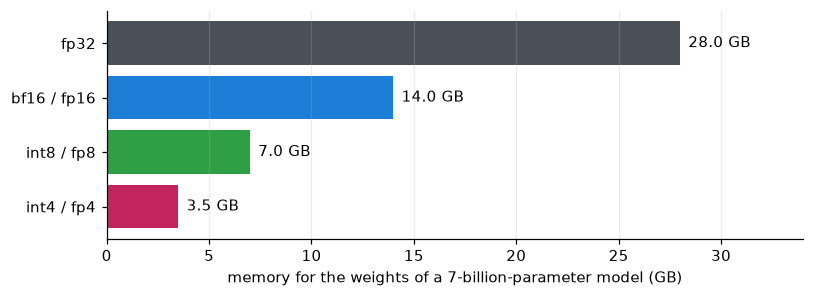

PASS - 7B params: fp32 = 28 GB, int4 = 3.5 GB 


In [2]:
BITS = {"fp32": 32, "bf16 / fp16": 16, "int8 / fp8": 8, "int4 / fp4": 4}
N = 7e9
fig, ax = plt.subplots(figsize=(7.5, 2.8))
names = list(BITS); gb = [N * b / 8 / 1e9 for b in BITS.values()]
bars = ax.barh(names[::-1], gb[::-1], color=["#c2255c", "#2f9e44", "#1c7ed6", "#495057"])
for b, v in zip(bars, gb[::-1]): ax.text(v + 0.4, b.get_y() + b.get_height() / 2, f"{v:.1f} GB", va="center")
ax.set_xlabel("memory for the weights of a 7-billion-parameter model (GB)"); ax.set_xlim(0, 34); ax.grid(axis="y", alpha=0)
plt.tight_layout(); plt.show()
check("7B params: fp32 = 28 GB, int4 = 3.5 GB", abs(gb[0] - 28) < 1e-9 and abs(gb[-1] - 3.5) < 1e-9)

Fewer bits also means less data to move between memory and compute units - on modern hardware that movement is often the real bottleneck. **The catch:** fewer bits can represent fewer distinct numbers (`2^bits` of them). The rest of the notebook is about *which* numbers you keep.

## Step 2 - Integers: bits, and the wheel

With **n bits** you get `2^n` patterns. For *unsigned* integers the pattern is just binary place value: `1011₂ = 8+2+1 = 11`.

For *signed* integers every modern machine uses **two's complement**: the top bit counts as **−2^(n−1)** instead of +2^(n−1). The picture to hold in your head is a **wheel**: the same 16 patterns, read two ways.

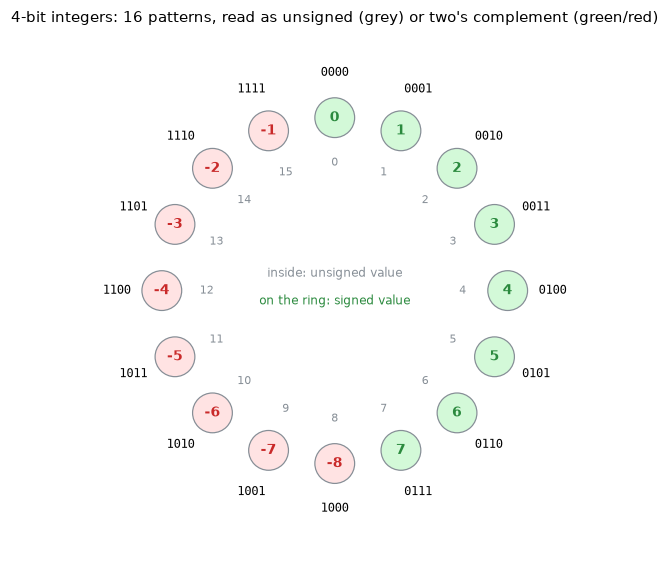

In [3]:
def wheel(ax, n=4):
    M = 2 ** n
    ax.set_aspect("equal"); ax.axis("off")
    for k in range(M):
        th = math.pi / 2 - 2 * math.pi * k / M                       # pattern k, clockwise from the top
        x, y = math.cos(th), math.sin(th)
        signed = k if k < M // 2 else k - M
        neg = signed < 0
        ax.add_patch(Circle((1.0 * x, 1.0 * y), 0.115, color="#ffe3e3" if neg else "#d3f9d8", ec="#868e96", lw=0.8))
        ax.text(1.0 * x, 1.0 * y, f"{signed}", ha="center", va="center", fontsize=9, color="#c92a2a" if neg else "#2b8a3e", fontweight="bold")
        ax.text(1.26 * x, 1.26 * y, format(k, f"0{n}b"), ha="center", va="center", fontsize=8, family="monospace")
        ax.text(0.74 * x, 0.74 * y, f"{k}", ha="center", va="center", fontsize=7.5, color="#868e96")
    ax.text(0, 0.08, "inside: unsigned value", ha="center", fontsize=8, color="#868e96")
    ax.text(0, -0.08, "on the ring: signed value", ha="center", fontsize=8, color="#2b8a3e")
    ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5)
fig, ax = plt.subplots(figsize=(5.2, 5.2)); wheel(ax)
ax.set_title("4-bit integers: 16 patterns, read as unsigned (grey) or two's complement (green/red)", fontsize=9.5)
plt.tight_layout(); plt.show()

Read the wheel: `0111` is **+7**, add one and you land on `1000`, which is **−8** - the number *wraps around*. That is why integer overflow does not crash; it silently flips sign. Ranges for `n` bits:

- unsigned: `0 … 2^n − 1`  - signed (two's complement): `−2^(n−1) … 2^(n−1) − 1` (one more negative than positive).

In [4]:
for dt, n in [(torch.int8, 8), (torch.uint8, 8), (torch.int16, 16), (torch.int32, 32)]:
    info = torch.iinfo(dt)
    signed = dt != torch.uint8
    exp_min, exp_max = (-2 ** (n - 1), 2 ** (n - 1) - 1) if signed else (0, 2 ** n - 1)
    print(f"{str(dt):13s} min={info.min:>12d} max={info.max:>11d}")
    assert (info.min, info.max) == (exp_min, exp_max)
check("iinfo ranges match -2^(n-1)..2^(n-1)-1 (and 0..2^n-1)", True)

x = torch.tensor([127], dtype=torch.int8)
wrapped = (x + 1).item()
print("int8: 127 + 1 =", wrapped, "   (wrap-around, no error raised)")
check("int8 127+1 wraps to -128", wrapped == -128)

# decode a pattern by hand: top bit weighs -2^(n-1)
def twos(bits_str):
    n = len(bits_str); v = int(bits_str, 2)
    return v - 2 ** n if bits_str[0] == "1" else v
check("hand decode: 1000=-8, 1111=-1, 0111=7 (4-bit)", (twos("1000"), twos("1111"), twos("0111")) == (-8, -1, 7))

torch.int8    min=        -128 max=        127
torch.uint8   min=           0 max=        255
torch.int16   min=      -32768 max=      32767
torch.int32   min= -2147483648 max= 2147483647
PASS - iinfo ranges match -2^(n-1)..2^(n-1)-1 (and 0..2^n-1) 
int8: 127 + 1 = -128    (wrap-around, no error raised)
PASS - int8 127+1 wraps to -128 
PASS - hand decode: 1000=-8, 1111=-1, 0111=7 (4-bit) 


### The limit of integers
An `int8` has 256 values and they are **evenly spaced**: 1, 2, 3 … . It cannot store 0.37, nor 1e-6, nor 3 000 000. A network's weights live around `0.02` and its activations can reach thousands, so we need numbers whose **spacing grows with size**. That is exactly what floating point is.

## Step 3 - Floating point: scientific notation in binary

You already know scientific notation: `−6.5 = −1.625 × 2²`. A float stores three things:

$$\text{value} = (-1)^{s}\;\times\;\underbrace{\left(1 + \tfrac{M}{2^{m}}\right)}_{\text{significand } 1.xxx}\;\times\;2^{\,E-\text{bias}}$$

| field | bits | role |
|---|---|---|
| **s** sign | 1 | 0 = positive, 1 = negative |
| **E** exponent | `e` | the power of two (stored with an offset `bias = 2^(e−1) − 1` so that it needs no sign) |
| **M** mantissa (fraction) | `m` | the digits after the point of `1.xxx`; the leading `1` is *implied*, not stored |

Two special rows of `E` get different rules: **E = 0** means *subnormal* (no implied 1, so numbers can shrink smoothly to zero) and **E = all ones** usually means *infinity / NaN*. Let's decode one number completely by hand, in the 8-bit format **E4M3** (4 exponent bits, 3 mantissa bits, bias 7):

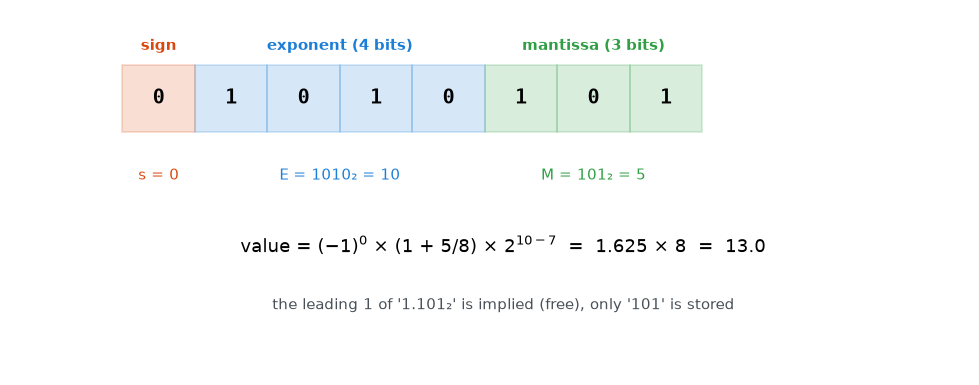

PyTorch reads the same byte as: 13.0
PASS - hand decode 0 1010 101 (E4M3) = 13.0 = PyTorch 


In [5]:
def draw_fields(ax, bits, e, m, x0=0.0, y0=0.0, w=0.62, h=0.62, show_idx=False):
    """Draw one row of bit boxes coloured sign / exponent / mantissa."""
    fields = [("s", 1, SIGN_C), ("exponent", e, EXP_C), ("mantissa", m, MAN_C)]
    k = 0
    for fname, cnt, col in fields:
        for _ in range(cnt):
            ax.add_patch(Rectangle((x0 + k * w, y0), w, h, fc=col, alpha=0.18, ec=col, lw=1.2))
            if bits is not None: ax.text(x0 + (k + .5) * w, y0 + h / 2, bits[k], ha="center", va="center", family="monospace", fontsize=13, fontweight="bold")
            k += 1
    return k

# --- anatomy figure: the bit pattern 0 1010 101 in E4M3 ---
pat = "01010101"
s, E, M = int(pat[0]), int(pat[1:5], 2), int(pat[5:], 2)
val = (-1) ** s * (1 + M / 8) * 2.0 ** (E - 7)
fig, ax = plt.subplots(figsize=(9, 3.6)); ax.axis("off"); ax.set_xlim(-0.3, 10); ax.set_ylim(-2.6, 1.6)
draw_fields(ax, pat, 4, 3, x0=0.9, y0=0.2, w=0.78, h=0.78)
w = 0.78
ax.text(0.9 + 0.5 * w, 1.15, "sign", ha="center", color=SIGN_C, fontweight="bold")
ax.text(0.9 + 3 * w, 1.15, "exponent (4 bits)", ha="center", color=EXP_C, fontweight="bold")
ax.text(0.9 + 6.5 * w, 1.15, "mantissa (3 bits)", ha="center", color=MAN_C, fontweight="bold")
ax.text(0.9 + 0.5 * w, -0.35, f"s = {s}", ha="center", color=SIGN_C)
ax.text(0.9 + 3 * w, -0.35, f"E = 1010₂ = {E}", ha="center", color=EXP_C)
ax.text(0.9 + 6.5 * w, -0.35, f"M = 101₂ = {M}", ha="center", color=MAN_C)
ax.text(5.0, -1.2, rf"value = (−1)$^{{{s}}}$ × (1 + {M}/8) × 2$^{{{E}-7}}$  =  {1 + M / 8} × {2 ** (E - 7)}  =  {val}", ha="center", fontsize=12)
ax.text(5.0, -1.85, "the leading 1 of '1.101₂' is implied (free), only '101' is stored", ha="center", fontsize=9.5, color="#495057")
plt.tight_layout(); plt.show()
t = torch.tensor([int(pat, 2)], dtype=torch.uint8).view(torch.float8_e4m3fn).float().item()
print("PyTorch reads the same byte as:", t)
check("hand decode 0 1010 101 (E4M3) = 13.0 = PyTorch", val == 13.0 == t)

Notice what the three fields do: **E picks the octave** (`[8,16)` here), **M picks one of 2^m evenly spaced points inside that octave**. With `m = 3` there are only 8 points between 8 and 16 - spacing 1.0. Flip a mantissa bit and the number changes by a little, flip an exponent bit and it changes by a factor of 2^k.

## Step 4 - The formats side by side

All of them share the layout `[ s | exponent | mantissa ]`; they only differ in how many bits go to each. *Box widths below are proportional to bit counts.*

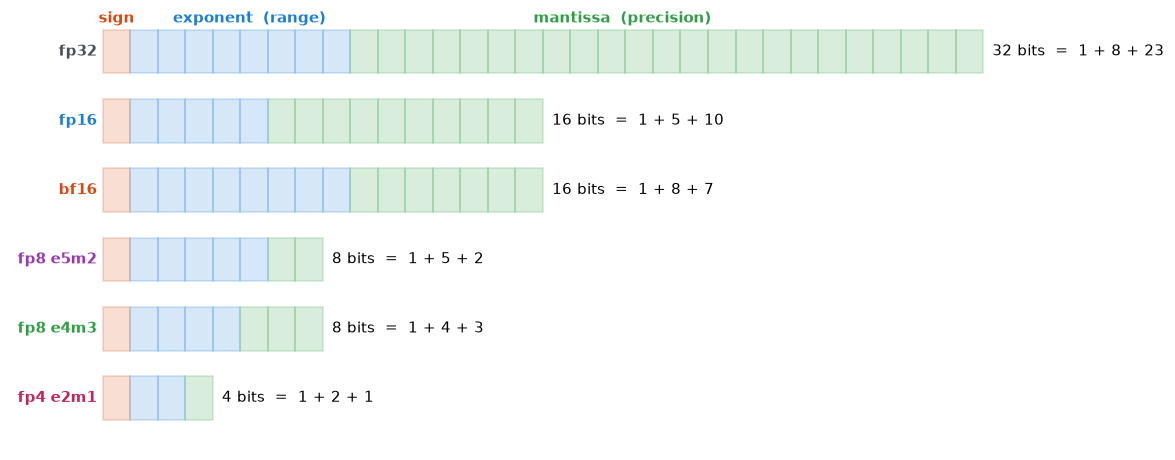

In [6]:
# name : (exp bits, man bits, bias, torch dtype, special-value rule)
FORMATS = {
    "fp32":     (8, 23, 127, torch.float32,       "ieee"),
    "fp16":     (5, 10, 15,  torch.float16,       "ieee"),
    "bf16":     (8, 7,  127, torch.bfloat16,      "ieee"),
    "fp8 e5m2": (5, 2,  15,  torch.float8_e5m2,   "ieee"),
    "fp8 e4m3": (4, 3,  7,   torch.float8_e4m3fn, "e4m3fn"),   # 'fn': finite + one NaN, no infinities
}
fig, ax = plt.subplots(figsize=(11, 4.3)); ax.axis("off"); ax.set_xlim(-3.0, 33); ax.set_ylim(-0.4, 5.6)
rows = list(FORMATS.items()) + [("fp4 e2m1", (2, 1, 1, None, "e2m1"))]
for r, (name, (e, m, b, _, _)) in enumerate(rows):
    y = 4.75 - r * 0.95; w = 0.9
    ax.text(-0.2, y + 0.3, name, ha="right", va="center", fontweight="bold", color=FMT_C[name])
    draw_fields(ax, None, e, m, x0=0.0, y0=y, w=w, h=0.6)
    tot = 1 + e + m
    ax.text(tot * w + 0.3, y + 0.3, f"{tot} bits  =  1 + {e} + {m}", va="center", fontsize=9.5)
for lab, c, x in [("sign", SIGN_C, 0.45), ("exponent  (range)", EXP_C, 4.8), ("mantissa  (precision)", MAN_C, 17)]:
    ax.text(x, 5.45, lab, color=c, fontweight="bold", ha="center")
plt.tight_layout(); plt.show()

Look at **fp16 vs bf16**: the same 16 bits, split differently. bf16 ("brain float", from Google Brain) is simply *fp32 with the bottom 16 mantissa bits cut off*, so it keeps fp32's exponent (range) and gives up precision. And **fp8 comes in two flavours** for the same reason: E4M3 favours precision, E5M2 favours range.

### A decoder, verified on every bit pattern
Instead of trusting the formula, write the decoder and compare it with PyTorch's own hardware-format casts on **all** 65 536 patterns of fp16 and bf16, all 256 of both fp8 types and 200 000 random fp32 patterns.

In [7]:
def decode(bits, e, m, bias, rule):
    """bits: integer array of raw patterns -> float64 values (NaN/inf handled per format rule)."""
    bits = np.asarray(bits, dtype=np.uint64)
    s = (bits >> np.uint64(e + m)) & np.uint64(1)
    E = ((bits >> np.uint64(m)) & np.uint64((1 << e) - 1)).astype(np.int64)
    M = (bits & np.uint64((1 << m) - 1)).astype(np.float64)
    sub = 2.0 ** (1 - bias) * (M / 2 ** m)                        # E == 0 : no implied leading 1
    nor = 2.0 ** (E.astype(np.float64) - bias) * (1 + M / 2 ** m)
    v = np.where(E == 0, sub, nor)
    top = (1 << e) - 1
    if rule == "ieee":
        v = np.where((E == top) & (M == 0), np.inf, v)
        v = np.where((E == top) & (M != 0), np.nan, v)
    elif rule == "e4m3fn":
        v = np.where((E == top) & (M == 2 ** m - 1), np.nan, v)   # only S.1111.111 is NaN
    return np.where(s == 1, -v, v)

def torch_decode_all(dtype, n_bits, n_sample=None, rng=np.random.default_rng(0)):
    if n_bits == 8:
        raw = np.arange(256, dtype=np.uint8); t = torch.from_numpy(raw.view(np.int8).copy()).view(dtype)
    elif n_bits == 16:
        raw = np.arange(65536, dtype=np.uint16); t = torch.from_numpy(raw.view(np.int16).copy()).view(dtype)
    else:
        raw = rng.integers(0, 2 ** 32, n_sample, dtype=np.uint64).astype(np.uint32); t = torch.from_numpy(raw.view(np.int32).copy()).view(dtype)
    return raw.astype(np.uint64), t.double().numpy()

for name, (e, m, b, dt, rule) in FORMATS.items():
    n_bits = 1 + e + m
    raw, ref = torch_decode_all(dt, n_bits, n_sample=200_000)
    mine = decode(raw, e, m, b, rule)
    same = np.array_equal(np.nan_to_num(mine, nan=-9e99), np.nan_to_num(ref, nan=-9e99))   # treat NaN == NaN
    check(f"{name}: my decoder == torch on {len(raw):,} patterns", same,
          f"{int(np.isnan(ref).sum())} NaN, {int(np.isinf(ref).sum())} inf")

PASS - fp32: my decoder == torch on 200,000 patterns | 749 NaN, 0 inf
PASS - fp16: my decoder == torch on 65,536 patterns | 2046 NaN, 2 inf
PASS - bf16: my decoder == torch on 65,536 patterns | 254 NaN, 2 inf
PASS - fp8 e5m2: my decoder == torch on 256 patterns | 6 NaN, 2 inf
PASS - fp8 e4m3: my decoder == torch on 256 patterns | 2 NaN, 0 inf


The decoder is eleven lines and agrees bit-for-bit with the hardware formats - so the formula in Step 3 *is* the format. Now the numbers that define each one:

In [8]:
rows = []
for name, (e, m, b, dt, rule) in FORMATS.items():
    if rule == "e4m3fn":   max_v = (2 - 2 ** (1 - m)) * 2.0 ** (2 ** e - 1 - b)     # top exponent usable, top mantissa is NaN
    elif rule == "ieee":   max_v = (2 - 2 ** -m) * 2.0 ** (2 ** e - 2 - b)          # top exponent reserved for inf/NaN
    min_norm, min_sub, eps = 2.0 ** (1 - b), 2.0 ** (1 - b - m), 2.0 ** -m
    fi = torch.finfo(dt)
    ok = (fi.max == max_v) and (fi.tiny == min_norm) and (fi.eps == eps)
    rows.append((name, 1 + e + m, e, m, max_v, min_norm, min_sub, eps, 2 ** (1 + e + m)))
    check(f"{name}: formulas for max / min-normal / eps match torch.finfo", ok)
print(f"{'format':9s}{'bits':>5s}{'e':>3s}{'m':>3s}{'max':>12s}{'min normal':>13s}{'min subnormal':>15s}{'eps (=2^-m)':>13s}  patterns")
for r in rows: print(f"{r[0]:9s}{r[1]:5d}{r[2]:3d}{r[3]:3d}{r[4]:12.5g}{r[5]:13.3g}{r[6]:15.3g}{r[7]:13.3g}  {r[8]:,}")

PASS - fp32: formulas for max / min-normal / eps match torch.finfo 
PASS - fp16: formulas for max / min-normal / eps match torch.finfo 
PASS - bf16: formulas for max / min-normal / eps match torch.finfo 
PASS - fp8 e5m2: formulas for max / min-normal / eps match torch.finfo 
PASS - fp8 e4m3: formulas for max / min-normal / eps match torch.finfo 
format    bits  e  m         max   min normal  min subnormal  eps (=2^-m)  patterns
fp32        32  8 23  3.4028e+38     1.18e-38        1.4e-45     1.19e-07  4,294,967,296
fp16        16  5 10       65504      6.1e-05       5.96e-08     0.000977  65,536
bf16        16  8  7  3.3895e+38     1.18e-38       9.18e-41      0.00781  65,536
fp8 e5m2     8  5  2       57344      6.1e-05       1.53e-05         0.25  256
fp8 e4m3     8  4  3         448       0.0156        0.00195        0.125  256


Reading the table: **max** and **min normal** = the *range*; **eps** = the *precision* (the gap between 1.0 and the next number: `2^-m`, i.e. roughly `m·0.3` decimal digits). Seven decimal digits for fp32, three for fp16, only **two** for bf16, and one for fp8.

Two details worth knowing:
- **E4M3 has no infinity** and only one NaN pattern, which buys it the range up to **448** instead of 240.
- **fp4 (E2M1)** has just 16 patterns - 8 non-negative values: `0, 0.5, 1, 1.5, 2, 3, 4, 6`. Let us verify that and look at *all* of them.

In [9]:
e, m, b = 2, 1, 1
fp4 = decode(np.arange(16), e, m, b, "e2m1")
pos = sorted(set(fp4[fp4 >= 0].tolist()))
print("fp4 e2m1 non-negative values:", pos)
check("fp4 e2m1 values = 0, .5, 1, 1.5, 2, 3, 4, 6", pos == [0, .5, 1, 1.5, 2, 3, 4, 6])

fp4 e2m1 non-negative values: [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0]
PASS - fp4 e2m1 values = 0, .5, 1, 1.5, 2, 3, 4, 6 


## Step 5 - The number line: where do the numbers actually sit?

A format can only store the numbers drawn as ticks below; everything else is **rounded to the nearest tick**. Left: a linear axis. Right: the same values on a log axis.

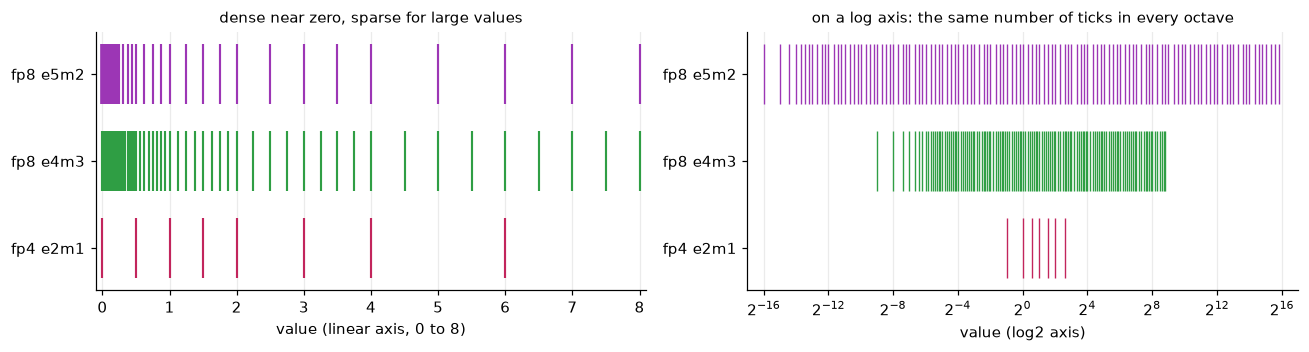

PASS - fp8 e4m3: exactly 2^m = 8 values in each normal octave | {0: 8, 1: 8}
PASS - fp8 e5m2: exactly 2^m = 4 values in each normal octave | {0: 4, 1: 4}
PASS - fp4 e2m1: exactly 2^m = 2 values in each normal octave | {0: 2, 1: 2}
e4m3 gap between neighbours in octave [2^k, 2^(k+1)): {0: 0.125, 1: 0.25, 2: 0.5, 3: 1.0}
PASS - spacing doubles every octave (e4m3 gaps 1/8, 1/4, 1/2, 1) 


In [10]:
def positive_values(name):
    e, m, b, dt, rule = FORMATS[name] if name in FORMATS else (2, 1, 1, None, "e2m1")
    v = decode(np.arange(2 ** (1 + e + m)), e, m, b, rule)
    return np.unique(v[np.isfinite(v) & (v >= 0)])

order = ["fp4 e2m1", "fp8 e4m3", "fp8 e5m2"]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.3))
for i, name in enumerate(order):
    v = positive_values(name)
    vv = v[v <= 8]
    axs[0].vlines(vv, i - 0.35, i + 0.35, color=FMT_C[name], lw=1.4)
    vl = v[v > 0]
    axs[1].vlines(vl, i - 0.35, i + 0.35, color=FMT_C[name], lw=0.9)
for ax in axs: ax.set_yticks(range(3)); ax.set_yticklabels(order); ax.grid(axis="y", alpha=0)
axs[0].set_xlim(-0.1, 8.1); axs[0].set_xlabel("value (linear axis, 0 to 8)")
axs[0].set_title("dense near zero, sparse for large values", fontsize=10)
axs[1].set_xscale("log", base=2); axs[1].set_xlim(2 ** -17, 2 ** 17); axs[1].set_xlabel("value (log2 axis)")
axs[1].set_title("on a log axis: the same number of ticks in every octave", fontsize=10)
plt.tight_layout(); plt.show()

# prove "2^m points per octave" and "spacing doubles every octave" instead of just claiming it
for name in ["fp8 e4m3", "fp8 e5m2", "fp4 e2m1"]:
    v = positive_values(name); e, m = (FORMATS[name][:2] if name in FORMATS else (2, 1))
    counts = {k: int(((v >= 2.0 ** k) & (v < 2.0 ** (k + 1))).sum()) for k in range(0, 2)}
    check(f"{name}: exactly 2^m = {2 ** m} values in each normal octave", all(c == 2 ** m for c in counts.values()), str(counts))
v = positive_values("fp8 e4m3")
gaps = {k: float(np.diff(v[(v >= 2.0 ** k) & (v <= 2.0 ** (k + 1))]).mean()) for k in range(0, 4)}
print("e4m3 gap between neighbours in octave [2^k, 2^(k+1)):", gaps)
check("spacing doubles every octave (e4m3 gaps 1/8, 1/4, 1/2, 1)", list(gaps.values()) == [0.125, 0.25, 0.5, 1.0])

**The key idea:** floats have **constant *relative* precision**. Between 1 and 2 an E4M3 number has 8 choices (step 1/8 = 12 % of the value); between 8 and 16 it still has 8 choices (step 1 = 12 % of the value). The *absolute* gap doubles every octave, the *relative* gap stays the same. That is what you want for numbers that span many orders of magnitude.

We can plot exactly that - the relative rounding error of each format as we sweep the magnitude (cast with PyTorch, compare to the true value):

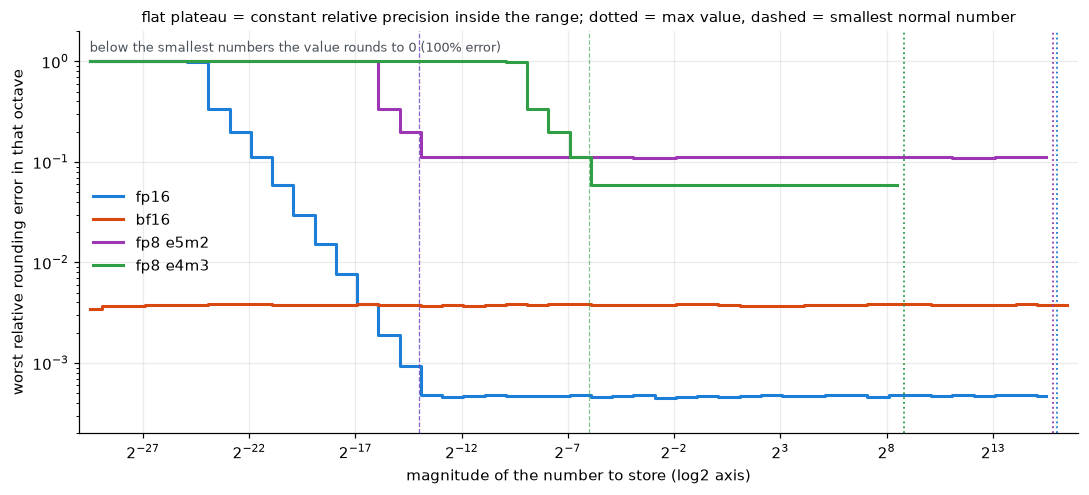

PASS - fp16: worst relative rounding error <= 2^-(m+1) = 0.0004883 | measured 0.0004838
PASS - bf16: worst relative rounding error <= 2^-(m+1) = 0.003906 | measured 0.003888
PASS - fp8 e5m2: worst relative rounding error <= 2^-(m+1) = 0.125 | measured 0.1111
PASS - fp8 e4m3: worst relative rounding error <= 2^-(m+1) = 0.0625 | measured 0.05882


In [11]:
xs = np.logspace(-9, 5, 40000)
fig, ax = plt.subplots(figsize=(10, 4.6))
for name, (e, m, b, dt, rule) in FORMATS.items():
    if name == "fp32": continue
    fi = torch.finfo(dt)
    sel = xs <= fi.max * 0.999
    x = torch.tensor(xs[sel], dtype=torch.float64)
    rel = ((x.to(dt).double() - x).abs() / x).numpy()
    octave = np.floor(np.log2(xs[sel])).astype(int)                    # worst error inside each octave [2^k, 2^(k+1))
    ks = np.unique(octave); worst = np.array([rel[octave == k].max() for k in ks])
    ax.step(2.0 ** (ks + 0.5), np.maximum(worst, 1e-4), where="mid", color=FMT_C[name], lw=2, label=name)
    ax.axvline(fi.max, color=FMT_C[name], ls=":", lw=1.2) if fi.max < 1e6 else None
    ax.axvline(fi.tiny, color=FMT_C[name], ls="--", lw=0.8, alpha=.6) if fi.tiny > 1e-12 else None
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlim(2.0 ** -30, 2.0 ** 17); ax.set_ylim(2e-4, 2)
ax.text(2.0 ** -29.5, 1.25, "below the smallest numbers the value rounds to 0 (100% error)", fontsize=8.5, color="#495057")
ax.set_xlabel("magnitude of the number to store (log2 axis)"); ax.set_ylabel("worst relative rounding error in that octave")
ax.set_title("flat plateau = constant relative precision inside the range; dotted = max value, dashed = smallest normal number", fontsize=9.5)
ax.legend(loc="center left", frameon=False)
plt.tight_layout(); plt.show()

# measured worst-case relative error in the normal range vs the theoretical 2^-(m+1)
for name, (e, m, b, dt, rule) in FORMATS.items():
    if name == "fp32": continue
    fi = torch.finfo(dt)
    sel = (xs > fi.tiny) & (xs < fi.max * 0.999)
    x = torch.tensor(xs[sel], dtype=torch.float64); rel = ((x.to(dt).double() - x).abs() / x).max().item()
    check(f"{name}: worst relative rounding error <= 2^-(m+1) = {2.0 ** -(m + 1):.4g}", rel <= 2.0 ** -(m + 1) * 1.0001, f"measured {rel:.4g}")

## Step 6 - Range vs precision: why fp16 ≠ bf16

Two independent properties:

- **Range** (how big / small can you go) comes from the **exponent** bits.
- **Precision** (how finely can you resolve values) comes from the **mantissa** bits.

Same 16 bits, opposite choices:

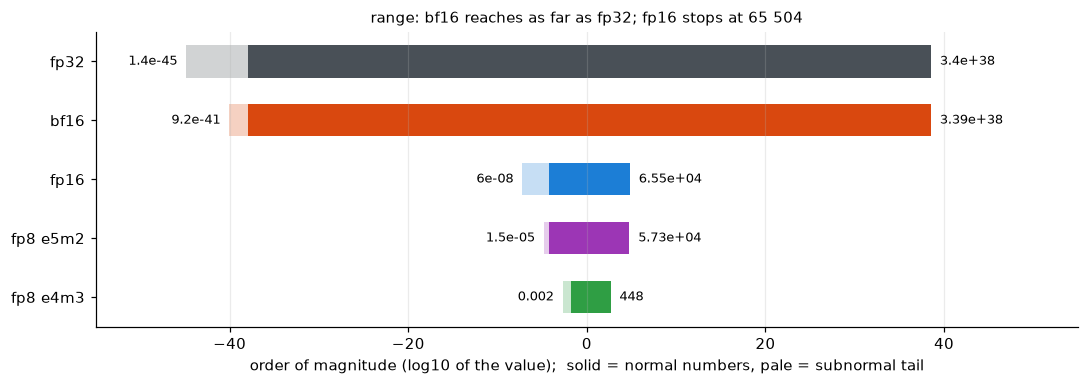

store 70000 ->  fp16: inf  bf16: 70144.0  (bf16 rounds it to a multiple of 512)
PASS - fp16 overflows 70000 to inf; bf16 keeps ~70144 
store 1.001 ->  fp16: 1.0009765625  bf16: 1.0  (bf16 cannot see the 0.001)
PASS - bf16 stores 1.001 as exactly 1.0, fp16 does not 


In [12]:
fig, ax = plt.subplots(figsize=(10, 3.6))
names = ["fp32", "bf16", "fp16", "fp8 e5m2", "fp8 e4m3"]
for i, name in enumerate(names):
    e, m, b, dt, rule = FORMATS[name]; fi = torch.finfo(dt)
    lo_sub, lo_n, hi = math.log10(2.0 ** (1 - b - m)), math.log10(fi.tiny), math.log10(fi.max)
    ax.barh(i, hi - lo_sub, left=lo_sub, color=FMT_C[name], alpha=0.25, height=0.55)
    ax.barh(i, hi - lo_n, left=lo_n, color=FMT_C[name], height=0.55)
    ax.text(hi + 1, i, f"{fi.max:.3g}", va="center", fontsize=8.5); ax.text(lo_sub - 1, i, f"{2.0 ** (1 - b - m):.2g}", va="center", ha="right", fontsize=8.5)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.invert_yaxis(); ax.set_xlim(-55, 55)
ax.set_xlabel("order of magnitude (log10 of the value);  solid = normal numbers, pale = subnormal tail"); ax.grid(axis="y", alpha=0)
ax.set_title("range: bf16 reaches as far as fp32; fp16 stops at 65 504", fontsize=10)
plt.tight_layout(); plt.show()

x = 70000.0
print("store 70000 ->  fp16:", torch.tensor(x).half().item(), " bf16:", torch.tensor(x).bfloat16().item(), " (bf16 rounds it to a multiple of 512)")
check("fp16 overflows 70000 to inf; bf16 keeps ~70144", torch.tensor(x).half().item() == math.inf and torch.tensor(x).bfloat16().item() == 70144.0)
y = 1.001
print("store 1.001 ->  fp16:", torch.tensor(y).half().item(), " bf16:", torch.tensor(y).bfloat16().item(), " (bf16 cannot see the 0.001)")
check("bf16 stores 1.001 as exactly 1.0, fp16 does not", torch.tensor(y).bfloat16().item() == 1.0 and torch.tensor(y).half().item() != 1.0)

**Rule of thumb:** bf16 trades precision for range, so training "just works" like fp32 (no overflow worries) but each number is blurrier. fp16 is more precise but overflows past 65 504, which needs extra care (Step 7). Both are 2 bytes.

## Step 7 - When it goes wrong

Four failure modes you will meet. Each is run for real below.

**(a) Not every decimal is representable.** `0.1` has no finite binary expansion, in *any* format:

In [13]:
from decimal import Decimal
print(f"{'format':9s} {'0.1 is stored as':44s} error")
for name, dt in [("fp64", torch.float64), ("fp32", torch.float32), ("fp16", torch.float16), ("bf16", torch.bfloat16), ("fp8 e4m3", torch.float8_e4m3fn)]:
    v = torch.tensor(0.1, dtype=torch.float64).to(dt).double().item()
    print(f"{name:9s} {str(Decimal(v)):44.44s} {v - 0.1:+.3e}")
print("\nclassic:  0.1 + 0.2 == 0.3 ?", 0.1 + 0.2 == 0.3, "   (", repr(0.1 + 0.2), ")")
check("0.1+0.2 != 0.3 in float64", (0.1 + 0.2) != 0.3)
a = torch.tensor(16777216.0)
check("fp32: 2^24 + 1 == 2^24 (integers above 2^24 are no longer all representable)", (a + 1).item() == a.item())

format    0.1 is stored as                             error
fp64      0.100000000000000005551115123125782702118158 +0.000e+00
fp32      0.100000001490116119384765625                +1.490e-09
fp16      0.0999755859375                              -2.441e-05
bf16      0.10009765625                                +9.766e-05
fp8 e4m3  0.1015625                                    +1.562e-03

classic:  0.1 + 0.2 == 0.3 ? False    ( 0.30000000000000004 )
PASS - 0.1+0.2 != 0.3 in float64 
PASS - fp32: 2^24 + 1 == 2^24 (integers above 2^24 are no longer all representable) 


**(b) Adding a small number to a big one does nothing.** Once the running sum is large, its *gap to the next number* exceeds the increment. Keep adding `1.0` to a sum, in each format, and watch it **freeze**:

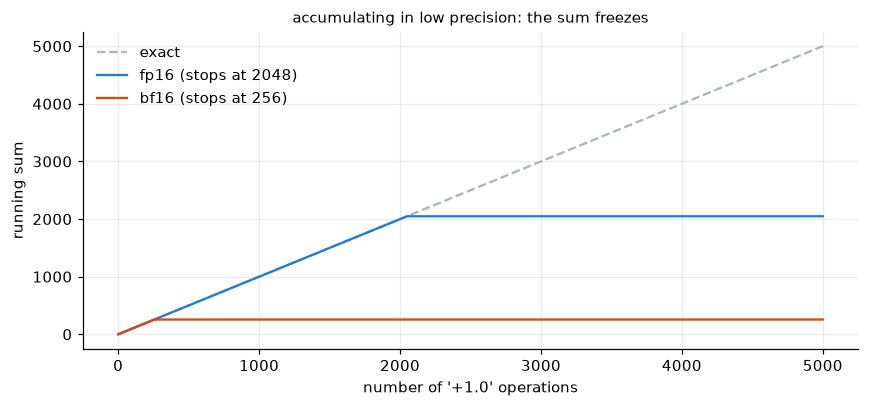

PASS - fp16 sum of ones freezes at 2048 (= 2^(m+1)) 
PASS - bf16 sum of ones freezes at 256 (= 2^(m+1)) 


In [14]:
def running_sum(dt, steps):
    s = torch.zeros((), dtype=dt); one = torch.ones((), dtype=dt); out = []
    for _ in range(steps):
        s = s + one; out.append(s.item())
    return np.array(out)

t16 = running_sum(torch.float16, 5000); tb = running_sum(torch.bfloat16, 5000)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(np.arange(1, 5001), np.arange(1, 5001), color="#adb5bd", ls="--", label="exact")
ax.plot(np.arange(1, 5001), t16, color=FMT_C["fp16"], label=f"fp16 (stops at {int(t16[-1])})")
ax.plot(np.arange(1, 5001), tb, color=FMT_C["bf16"], label=f"bf16 (stops at {int(tb[-1])})")
ax.set_xlabel("number of '+1.0' operations"); ax.set_ylabel("running sum"); ax.legend(frameon=False)
ax.set_title("accumulating in low precision: the sum freezes", fontsize=10)
plt.tight_layout(); plt.show()
check("fp16 sum of ones freezes at 2048 (= 2^(m+1))", t16[-1] == 2048 and t16[2200] == 2048)
check("bf16 sum of ones freezes at 256 (= 2^(m+1))", tb[-1] == 256)

At 2048 an fp16 number's neighbours are 2 apart (`2^11 × 2^-10`), so `2048 + 1` is a tie that rounds back to 2048 - forever. This is why **hardware accumulates in fp32** even when the inputs are fp16/bf16/fp8, and why summing millions of values (a loss, a softmax denominator, a long dot product) is done in higher precision.

**(c) Overflow.** `exp(12)` ≈ 162 755 is fine in fp32 and bf16 but **inf** in fp16. This is why softmax subtracts the row maximum before exponentiating:

In [15]:
z = torch.tensor(12.0)
for name, dt in [("fp32", torch.float32), ("bf16", torch.bfloat16), ("fp16", torch.float16)]:
    print(f"exp(12) in {name}: {torch.exp(z.to(dt)).item()}")
check("exp(12) overflows in fp16 only", torch.isinf(torch.exp(z.half())).item() and not torch.isinf(torch.exp(z.bfloat16())).item())
logits = torch.tensor([14.0, 13.0, 12.0]).half()
naive = torch.exp(logits) / torch.exp(logits).sum()
stable = torch.exp(logits - logits.max()); stable = stable / stable.sum()
print("softmax([14,13,12]) in fp16  naive :", naive.tolist(), "\n                          stable:", [round(v, 4) for v in stable.tolist()])
check("naive fp16 softmax gives NaN, max-subtracted version is fine", torch.isnan(naive).all().item() and abs(stable.sum().item() - 1) < 1e-2)

exp(12) in fp32: 162754.796875
exp(12) in bf16: 162816.0
exp(12) in fp16: inf
PASS - exp(12) overflows in fp16 only 
softmax([14,13,12]) in fp16  naive : [nan, nan, nan] 
                          stable: [0.6655, 0.2448, 0.0901]
PASS - naive fp16 softmax gives NaN, max-subtracted version is fine 


**(d) Underflow, and the trick that fixes it - loss scaling.** Gradients are often tiny. The smallest fp16 number is `6e-8`; anything smaller becomes **0**, and those weights stop learning. The fix used in fp16 mixed-precision training: multiply the loss (hence every gradient) by a big factor, e.g. 2¹⁶, run backward in fp16, then divide by the same factor in fp32.

true     : ['1e-09', '1e-08', '3e-08', '1e-06', '1e-04']
fp16     : ['0.0e+00', '0.0e+00', '6.0e-08', '1.0e-06', '1.0e-04'] <- tiny ones flushed to 0
scaled   : ['1.0e-09', '1.0e-08', '3.0e-08', '1.0e-06', '1.0e-04'] <- recovered
PASS - without scaling 1e-8 underflows to 0 in fp16 
PASS - with 2^16 scaling the 1e-8 gradient survives (<5% error) 
PASS - bf16 has fp32's range, so it needs no loss scaling for these | all five survive, but each is only ~2 digits accurate


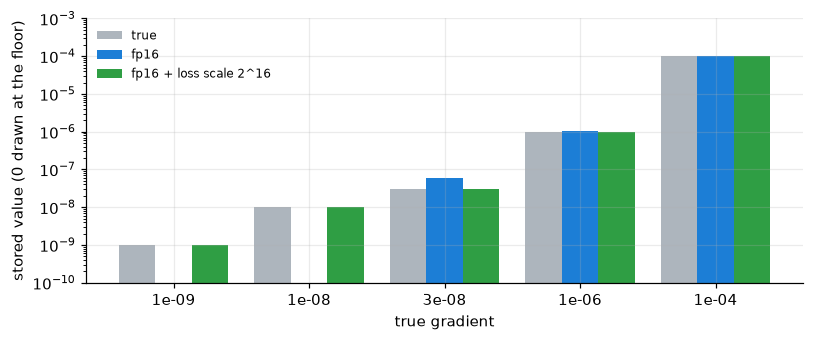

In [16]:
g = torch.tensor([1e-9, 1e-8, 3e-8, 1e-6, 1e-4])                      # "true" gradient values (fp32)
plain = g.half().float()
S = 2.0 ** 16
scaled = (g * S).half().float() / S
print("true     :", [f"{v:.0e}" for v in g.tolist()])
print("fp16     :", [f"{v:.1e}" for v in plain.tolist()], "<- tiny ones flushed to 0")
print("scaled   :", [f"{v:.1e}" for v in scaled.tolist()], "<- recovered")
check("without scaling 1e-8 underflows to 0 in fp16", plain[1].item() == 0.0)
check("with 2^16 scaling the 1e-8 gradient survives (<5% error)", abs(scaled[1].item() - 1e-8) / 1e-8 < 0.05)
bf = g.bfloat16().float()
check("bf16 has fp32's range, so it needs no loss scaling for these", (bf > 0).all().item(), "all five survive, but each is only ~2 digits accurate")
fig, ax = plt.subplots(figsize=(7.5, 3.2)); xs_ = np.arange(len(g)); wd = 0.27
ax.bar(xs_ - wd, np.maximum(g.numpy(), 1e-12), wd, label="true", color="#adb5bd")
ax.bar(xs_, np.maximum(plain.numpy(), 1e-12), wd, label="fp16", color=FMT_C["fp16"])
ax.bar(xs_ + wd, np.maximum(scaled.numpy(), 1e-12), wd, label="fp16 + loss scale 2^16", color="#2f9e44")
ax.set_yscale("log"); ax.set_ylim(1e-10, 1e-3); ax.set_xticks(xs_); ax.set_xticklabels([f"{v:.0e}" for v in g.tolist()])
ax.set_xlabel("true gradient"); ax.set_ylabel("stored value (0 drawn at the floor)"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Practical summary of Step 7:** keep **master weights and accumulators in fp32**, do the heavy matrix maths in bf16 / fp16 / fp8, and (for fp16) scale the loss. This is the idea behind *mixed-precision training* - conventionally about 16 bytes per parameter with Adam (2 for the bf16/fp16 weight copy, 2 for its gradient, 12 for fp32 master weights + the two Adam moments; see the ZeRO paper, Rajbhandari et al. 2020).

## Step 8 - Quantization: squeezing trained weights into 8 or 4 bits

After training you can often store the weights in **int8 / int4 / fp4** and lose little accuracy. The idea: choose a **scale** `s`, store small integers `q = round(w / s)`, and recover `w ≈ q · s`.

The whole game is picking `s`. If one huge outlier sets the scale, every normal weight gets rounded onto a handful of levels. Let us measure that with a toy weight matrix: Gaussian weights with std 0.02 (typical of a trained layer) plus 16 large outliers - outliers are a known problem in large language models (e.g. Dettmers et al., LLM.int8(), 2022).

In [17]:
torch.manual_seed(1)
W = torch.randn(1024, 64) * 0.02                                       # 65,536 weights
out_idx = torch.randperm(W.numel())[:16]
W.view(-1)[out_idx] = torch.sign(torch.randn(16)) * (0.6 + 0.4 * torch.rand(16))   # |outlier| in [0.6, 1.0]
Wc = (torch.randn(1024, 64) * 0.02)                                    # a clean control without outliers

NF4 = torch.tensor([-1.0, -0.6962, -0.5251, -0.3949, -0.2844, -0.1848, -0.0911, 0.0,
                    0.0796, 0.1609, 0.2461, 0.3379, 0.4407, 0.5626, 0.7230, 1.0])   # codebook as published in QLoRA (Dettmers 2023)
FP4 = torch.tensor([0, .5, 1, 1.5, 2, 3, 4, 6]); FP4 = torch.cat([-FP4.flip(0)[:-1], FP4])   # 15 distinct values (+-0 merged)

def absmax_blocks(w, block):
    wb = w.reshape(-1, w.numel() if block is None else block)
    return wb, wb.abs().amax(1, keepdim=True).clamp_min(1e-12)

def q_int(w, bits, block=None):
    qmax = 2 ** (bits - 1) - 1
    wb, am = absmax_blocks(w, block); s = am / qmax
    return (torch.round(wb / s).clamp(-qmax, qmax) * s).reshape(w.shape)

def q_codebook(w, code, block=64):
    wb, am = absmax_blocks(w, block); u = wb / am                    # u in [-1, 1]
    idx = (u.unsqueeze(-1) - code).abs().argmin(-1)
    return (code[idx] * am).reshape(w.shape)

def q_fp4(w, block=64):
    wb, am = absmax_blocks(w, block); s = am / 6.0
    idx = ((wb / s).unsqueeze(-1) - FP4).abs().argmin(-1)
    return (FP4[idx] * s).reshape(w.shape)

def mse(a, b): return ((a - b) ** 2).mean().item()
schemes = {
    "int8  per-tensor": lambda w: q_int(w, 8),
    "int8  block-64":   lambda w: q_int(w, 8, 64),
    "int4  per-tensor": lambda w: q_int(w, 4),
    "int4  block-64":   lambda w: q_int(w, 4, 64),
    "fp4   block-64":   lambda w: q_fp4(w, 64),
    "nf4   block-64":   lambda w: q_codebook(w, NF4, 64),
}
res = {k: (mse(f(W), W), mse(f(Wc), Wc)) for k, f in schemes.items()}
var = W.var().item(); varc = Wc.var().item()
print(f"{'scheme':18s}{'MSE w/ outliers':>18s}{'MSE clean':>14s}   (signal-to-noise on clean, dB)")
for k, (a, c) in res.items(): print(f"{k:18s}{a:18.3e}{c:14.3e}   {10 * math.log10(varc / c):6.1f}")

scheme               MSE w/ outliers     MSE clean   (signal-to-noise on clean, dB)
int8  per-tensor           5.081e-06     5.076e-08     39.0
int8  block-64             6.627e-08     1.412e-08     44.6
int4  per-tensor           4.025e-04     1.666e-05     13.8
int4  block-64             1.039e-05     4.616e-06     19.4
fp4   block-64             8.789e-06     4.490e-06     19.5
nf4   block-64             7.724e-06     3.401e-06     20.7


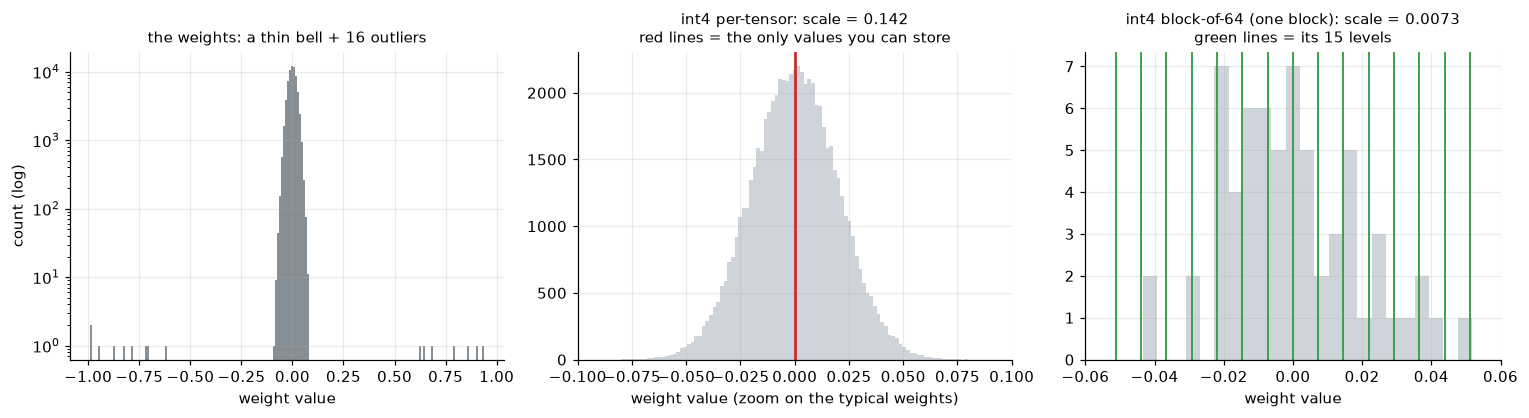

fraction of weights that int4 per-tensor does NOT round to zero: 0.1%
PASS - per-tensor int4 with outliers rounds >95% of the weights to exactly 0 | 0.1% non-zero


In [18]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.9), gridspec_kw={"width_ratios": [1.15, 1.15, 1.1]})
ax = axs[0]
ax.hist(W.view(-1).numpy(), bins=200, color="#868e96"); ax.set_yscale("log")
ax.set_title("the weights: a thin bell + 16 outliers", fontsize=10); ax.set_xlabel("weight value"); ax.set_ylabel("count (log)")
# --- what int4 per-tensor does to the typical weights
ax = axs[1]
s_t = W.abs().max().item() / 7; levels = np.arange(-7, 8) * s_t
ax.hist(W.view(-1).numpy(), bins=np.linspace(-0.1, 0.1, 120), color="#ced4da")
for L in levels:
    if abs(L) < 0.12: ax.axvline(L, color="#c92a2a", lw=1.8)
ax.set_xlim(-0.1, 0.1); ax.set_title(f"int4 per-tensor: scale = {s_t:.3f}\nred lines = the only values you can store", fontsize=10)
ax.set_xlabel("weight value (zoom on the typical weights)")
nz = (q_int(W, 4) != 0).float().mean().item()
# --- same weights, a block without outliers: its own scale
ax = axs[2]
blk = W.reshape(-1, 64); k = int((blk.abs().amax(1) < 0.2).nonzero()[0]); wb = blk[k]
s_b = wb.abs().max().item() / 7
ax.hist(wb.numpy(), bins=np.linspace(-0.06, 0.06, 30), color="#ced4da")
for L in np.arange(-7, 8) * s_b: ax.axvline(L, color="#2f9e44", lw=1.2)
ax.set_xlim(-0.06, 0.06); ax.set_title(f"int4 block-of-64 (one block): scale = {s_b:.4f}\ngreen lines = its 15 levels", fontsize=10)
ax.set_xlabel("weight value")
plt.tight_layout(); plt.show()
print(f"fraction of weights that int4 per-tensor does NOT round to zero: {nz:.1%}")
check("per-tensor int4 with outliers rounds >95% of the weights to exactly 0", nz < 0.05, f"{nz:.1%} non-zero")

With the outliers present, the per-tensor int4 scale is ~0.14 - larger than almost every real weight - so **almost the entire matrix collapses to 0**. Computing one scale per **block of 64** weights confines the damage of an outlier to its own block. Now the error numbers:

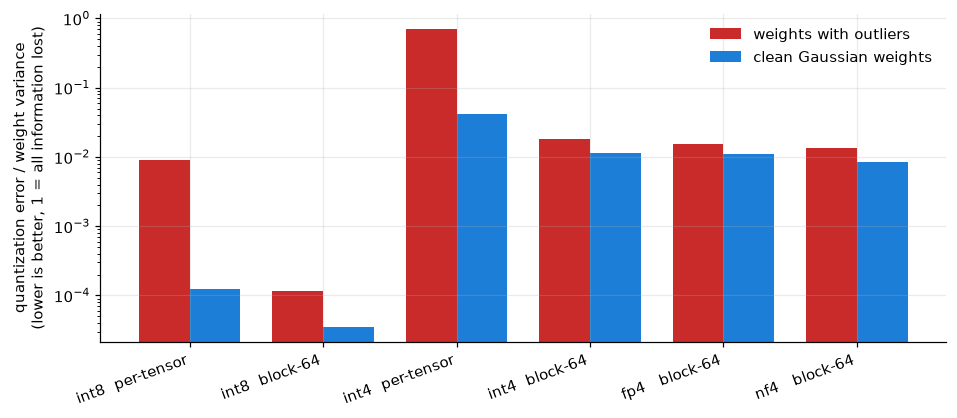

PASS - int8 per-tensor already loses little (<1% of variance) | 0.90%
PASS - outliers hurt per-tensor int4 far more than block-64 (>20x worse) | 0.712 vs 0.0184
PASS - block scaling makes int4 usable (<5% of variance) | 1.84%
PASS - on clean Gaussian weights NF4 beats uniform int4 (both block-64) | 0.0084 vs 0.0115
PASS - int8 beats int4 (more levels = less error) 


In [19]:
fig, ax = plt.subplots(figsize=(8.8, 3.9))
ks = list(res); xs_ = np.arange(len(ks)); wd = 0.38
ax.bar(xs_ - wd / 2, [res[k][0] / var for k in ks], wd, color="#c92a2a", label="weights with outliers")
ax.bar(xs_ + wd / 2, [res[k][1] / varc for k in ks], wd, color="#1c7ed6", label="clean Gaussian weights")
ax.set_yscale("log"); ax.set_xticks(xs_); ax.set_xticklabels(ks, rotation=20, ha="right")
ax.set_ylabel("quantization error / weight variance\n(lower is better, 1 = all information lost)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

r = {k: v[0] / var for k, v in res.items()}; rc = {k: v[1] / varc for k, v in res.items()}
check("int8 per-tensor already loses little (<1% of variance)", r["int8  per-tensor"] < 0.01, f"{r['int8  per-tensor']:.2%}")
check("outliers hurt per-tensor int4 far more than block-64 (>20x worse)", r["int4  per-tensor"] > 20 * r["int4  block-64"], f"{r['int4  per-tensor']:.3g} vs {r['int4  block-64']:.3g}")
check("block scaling makes int4 usable (<5% of variance)", r["int4  block-64"] < 0.05, f"{r['int4  block-64']:.2%}")
check("on clean Gaussian weights NF4 beats uniform int4 (both block-64)", rc["nf4   block-64"] < rc["int4  block-64"], f"{rc['nf4   block-64']:.4f} vs {rc['int4  block-64']:.4f}")
check("int8 beats int4 (more levels = less error)", r["int8  block-64"] < r["int4  block-64"])

What each variant does:
- **Per-tensor int8**: one scale for the whole matrix. Easy, fast, fine for int8, fragile for int4.
- **Block-wise (here 64)**: one scale per small block, stored alongside. Costs a little extra memory (a 16-bit scale per 64 weights = +0.25 bit/weight) and bounds how far an outlier can spread.
- **fp4 / NF4**: instead of *evenly spaced* levels use a **non-uniform codebook**. fp4's levels (0.5, 1, 1.5, 2, 3, 4, 6) are denser near zero like the float number line of Step 5; NF4 (*NormalFloat*, QLoRA) places its 16 levels at the **quantiles of a normal distribution**, because trained weights are roughly bell-shaped. Look at where the levels sit:

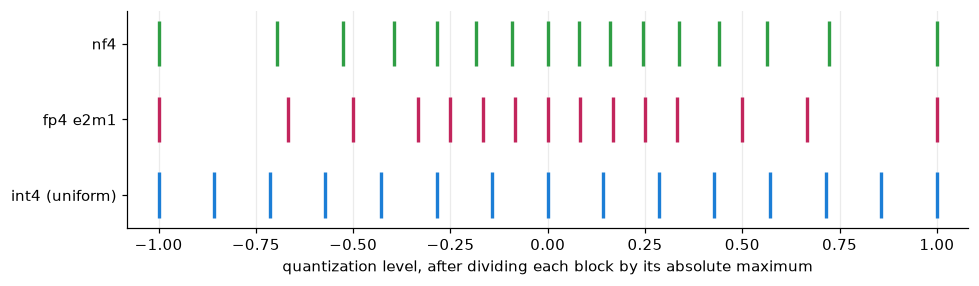

PASS - NF4 codebook: 16 sorted levels in [-1, 1] with an exact zero 


In [20]:
fig, ax = plt.subplots(figsize=(9, 2.7))
for i, (nm, lv, col) in enumerate([("int4 (uniform)", torch.arange(-7, 8) / 7, "#1c7ed6"), ("fp4 e2m1", FP4 / 6, FMT_C["fp4 e2m1"]), ("nf4", NF4, "#2f9e44")]):
    ax.vlines(lv.numpy(), i - .3, i + .3, color=col, lw=2.2)
ax.set_yticks(range(3)); ax.set_yticklabels(["int4 (uniform)", "fp4 e2m1", "nf4"]); ax.grid(axis="y", alpha=0)
ax.set_xlabel("quantization level, after dividing each block by its absolute maximum"); ax.set_xlim(-1.08, 1.08)
plt.tight_layout(); plt.show()
check("NF4 codebook: 16 sorted levels in [-1, 1] with an exact zero", len(NF4) == 16 and (NF4.diff() > 0).all().item() and 0.0 in NF4.tolist())

## Step 9 - How much error does a matrix multiply pick up?

Everything in a transformer is a matmul. Take two random matrices, compute `A @ B` exactly in float64, then again after storing the inputs in each format (the product is accumulated in fp32 - as hardware does - except for the native bf16 / fp16 CPU kernels).

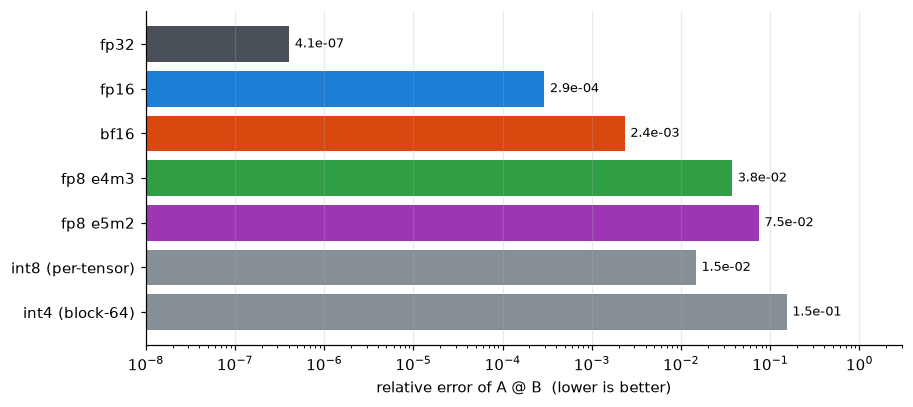

PASS - error order: fp32 < fp16 < bf16 < fp8 e4m3 < fp8 e5m2 
PASS - fp16 -> bf16 drops 3 mantissa bits, so the error grows ~2^3 = 8x | measured 8.0x


In [21]:
torch.manual_seed(2)
A = torch.randn(256, 512, dtype=torch.float64); B = torch.randn(512, 256, dtype=torch.float64)
ref = A @ B
def rel_err(C): return ((C.double() - ref).norm() / ref.norm()).item()
def via(dt):                                   # store inputs in dt, multiply in fp32
    return rel_err(A.to(dt).float() @ B.to(dt).float())
results = {
    "fp32":      rel_err(A.float() @ B.float()),
    "fp16":      via(torch.float16),
    "bf16":      via(torch.bfloat16),
    "fp8 e4m3":  via(torch.float8_e4m3fn),
    "fp8 e5m2":  via(torch.float8_e5m2),
    "int8 (per-tensor)": rel_err(q_int(A.float(), 8) @ q_int(B.float(), 8)),
    "int4 (block-64)":   rel_err(q_int(A.float(), 4, 64) @ q_int(B.float(), 4, 64)),
}
fig, ax = plt.subplots(figsize=(8.4, 3.8))
cols = [FMT_C.get(k, "#868e96") for k in results]
ax.barh(list(results)[::-1], list(results.values())[::-1], color=cols[::-1]); ax.set_xscale("log")
for i, v in enumerate(list(results.values())[::-1]): ax.text(v * 1.15, i, f"{v:.1e}", va="center", fontsize=8.5)
ax.set_xlabel("relative error of A @ B  (lower is better)"); ax.set_xlim(1e-8, 3); ax.grid(axis="y", alpha=0)
plt.tight_layout(); plt.show()
check("error order: fp32 < fp16 < bf16 < fp8 e4m3 < fp8 e5m2", results["fp32"] < results["fp16"] < results["bf16"] < results["fp8 e4m3"] < results["fp8 e5m2"])
ratio = results["bf16"] / results["fp16"]
check("fp16 -> bf16 drops 3 mantissa bits, so the error grows ~2^3 = 8x", 6 < ratio < 11, f"measured {ratio:.1f}x")

Every mantissa bit removed doubles the error (fp16 → bf16 drops 3 bits: ~8×, measured above). Note per-tensor **int8 is much noisier than fp16 here**: 256 evenly spaced levels stretched over a Gaussian whose rare 4-5σ values set the scale leave typical values coarsely quantized. fp8 and int4 are far noisier **on random Gaussian inputs, which is the worst case**; in trained networks, quantization-aware calibration, per-block scales and keeping a few sensitive layers in higher precision are what make 8-bit and 4-bit models work in practice. Whether a given model keeps its accuracy at 4 bits is an empirical question this notebook does not test.

## Step 10 - Cheat sheet

In [22]:
print(f"{'format':10s}{'bytes':>6s}{'max':>11s}{'eps':>10s}  typical use (common practice, not measured here)")
use = {"fp32": "master weights, optimizer state, accumulators", "fp16": "mixed-precision training / inference (needs loss scaling)",
       "bf16": "training and inference default on recent GPUs/TPUs/Apple silicon", "fp8 e4m3": "weights & activations in fp8 matmuls (forward)",
       "fp8 e5m2": "gradients in fp8 training (more range)"}
for name, (e, m, b, dt, rule) in FORMATS.items():
    fi = torch.finfo(dt); print(f"{name:10s}{(1 + e + m) // 8:6d}{fi.max:11.4g}{fi.eps:10.2g}  {use[name]}")
print(f"{'int8':10s}{1:6d}{127:11d}{'1 (step)':>10s}  quantised weights / activations (+ a scale)")
print(f"{'int4/fp4/nf4':10s}{0.5:6.1f}{'':11s}{'':10s}  weight-only quantisation, block scales, e.g. QLoRA")
check("cheat sheet bytes: fp32=4, fp16=bf16=2, fp8=1", [(1 + e + m) // 8 for (e, m, *_) in FORMATS.values()] == [4, 2, 2, 1, 1])

format     bytes        max       eps  typical use (common practice, not measured here)
fp32           4  3.403e+38   1.2e-07  master weights, optimizer state, accumulators
fp16           2   6.55e+04   0.00098  mixed-precision training / inference (needs loss scaling)
bf16           2   3.39e+38    0.0078  training and inference default on recent GPUs/TPUs/Apple silicon
fp8 e5m2       1  5.734e+04      0.25  gradients in fp8 training (more range)
fp8 e4m3       1        448      0.12  weights & activations in fp8 matmuls (forward)
int8           1        127  1 (step)  quantised weights / activations (+ a scale)
int4/fp4/nf4   0.5                       weight-only quantisation, block scales, e.g. QLoRA
PASS - cheat sheet bytes: fp32=4, fp16=bf16=2, fp8=1 


**One-line memory aid** - exponent bits = range, mantissa bits = precision:

| | exponent bits (range) | mantissa bits (precision) |
|---|---|---|
| fp32 | 8 | 23 |
| bf16 | 8 | 7 |
| fp16 | 5 | 10 |
| fp8 E5M2 | 5 | 2 |
| fp8 E4M3 | 4 | 3 |
| fp4 E2M1 | 2 | 1 |

In [23]:
print(f"{'#':>2s}  {'status':6s}  check")
for i, (n, ok, d) in enumerate(CHECKS, 1): print(f"{i:2d}  {'PASS' if ok else 'FAIL':6s}  {n}")
failed = [n for n, ok, _ in CHECKS if not ok]
print(f"\n{len(CHECKS) - len(failed)} passed, {len(failed)} failed")
assert not failed, failed

 #  status  check
 1  PASS    7B params: fp32 = 28 GB, int4 = 3.5 GB
 2  PASS    iinfo ranges match -2^(n-1)..2^(n-1)-1 (and 0..2^n-1)
 3  PASS    int8 127+1 wraps to -128
 4  PASS    hand decode: 1000=-8, 1111=-1, 0111=7 (4-bit)
 5  PASS    hand decode 0 1010 101 (E4M3) = 13.0 = PyTorch
 6  PASS    fp32: my decoder == torch on 200,000 patterns
 7  PASS    fp16: my decoder == torch on 65,536 patterns
 8  PASS    bf16: my decoder == torch on 65,536 patterns
 9  PASS    fp8 e5m2: my decoder == torch on 256 patterns
10  PASS    fp8 e4m3: my decoder == torch on 256 patterns
11  PASS    fp32: formulas for max / min-normal / eps match torch.finfo
12  PASS    fp16: formulas for max / min-normal / eps match torch.finfo
13  PASS    bf16: formulas for max / min-normal / eps match torch.finfo
14  PASS    fp8 e5m2: formulas for max / min-normal / eps match torch.finfo
15  PASS    fp8 e4m3: formulas for max / min-normal / eps match torch.finfo
16  PASS    fp4 e2m1 values = 0, .5, 1, 1.5, 2, 3, 4, 6

## Takeaways

1. **A format is a budget of bits.** Integers: evenly spaced. Floats: `[sign | exponent | mantissa]` = *range* (exponent) × *precision* (mantissa), with constant **relative** precision.
2. **The decoder is eleven lines** and matches PyTorch on every bit pattern (Step 4); there is no magic in fp16/bf16/fp8.
3. **bf16 vs fp16**: same size, bf16 keeps fp32's range and loses digits; fp16 keeps digits and overflows at 65 504.
4. **Low precision breaks in three ways**: values are rounded (0.1), sums freeze (2048 in fp16, 256 in bf16), and tiny/huge values underflow/overflow - hence fp32 accumulators, loss scaling, max-subtracted softmax.
5. **Quantization is "pick a scale"**: outliers make a single scale disastrous at 4 bits; block-wise scales and non-uniform codebooks (fp4, NF4) fix most of it.

### Exercises
- Write `encode(x, e, m, bias)` (the inverse of `decode`) with round-to-nearest-even and test it against `torch.tensor(x).to(dtype)`.
- Add a *stochastic rounding* quantizer and show it removes the "stuck sum" of Step 7(b) on average.
- Change the outlier magnitude in Step 8 and find the value where per-tensor int8 starts to hurt.
- Find the smallest block size at which int4 error stops improving.

### Honest limits
Everything here is measured on CPU with PyTorch's reference casts and **synthetic** data (random Gaussians, a toy weight matrix). Real hardware (tensor cores, fp8 kernels) adds its own accumulation and rounding behaviour, and accuracy-after-quantization of a real trained model is not tested. The NF4 levels are copied from the QLoRA paper, not recomputed. The memory table counts weights only (no activations, KV cache, optimizer state).